# Training Data Exploration and LST Trend Analysis

This notebook describes the data before modelling and recreates a descriptive, season-adjusted LST trend. It uses **development (training) locations only** and **April 2013–December 2021 only**. It does not load 2022 validation observations or 2023–2024 final-evaluation outcomes.

The unit is one pixel in one month. Missing measurements stay missing; plots do not fill gaps or remove extreme values. The analyses describe patterns, not causes or model performance.

Run the cells from top to bottom. The notebook reads the Parquet in batches and stores only training-period NDVI/LST values in memory. It saves the analysis figures and the monthly trend table under `reports/`.

In [10]:
from pathlib import Path
import calendar

import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent

EXTRACT_PATH = ROOT / "outputs/evergreen_reference_sample_recreated.parquet"
SOURCE_DIR = ROOT / "data/source"
FIGURE_DIR = ROOT / "reports/Figs"
MONTHLY_TABLE_PATH = ROOT / "reports/training_monthly_lst_means.csv"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
if not EXTRACT_PATH.is_file():
    raise FileNotFoundError(f"Run scripts/recreate_reference_sample.py first: {EXTRACT_PATH}")

FIRST_DATE = pd.Timestamp("2013-04-01")
LAST_DATE = pd.Timestamp("2021-12-01")
DATES = pd.date_range(FIRST_DATE, LAST_DATE, freq="MS")
MONTH_NUMBERS = DATES.month.to_numpy()
TRAINING_START_YEAR = 2013
TRAINING_MONTHS = len(DATES)
READ_BATCH_SIZE = 250_000
print(f"Training window: {FIRST_DATE:%Y-%m} through {LAST_DATE:%Y-%m} ({TRAINING_MONTHS} months)")

Training window: 2013-04 through 2021-12 (105 months)


## 1. Build the training-only panel

The filter is applied while reading: only development locations with the stored `fit` calendar role are included. A separate 2013 read identifies those locations and their coordinates. The two matrices below have one row per location and one column per training month.

In [11]:
first_year = pq.read_table(
    EXTRACT_PATH,
    columns=["pixel_id", "year", "calendar_role", "geographic_split", "lon", "lat"],
    filters=[
        ("year", "=", 2013),
        ("calendar_role", "=", "fit"),
        ("geographic_split", "=", "development"),
    ],
).to_pandas()
locations = (
    first_year[["pixel_id", "lon", "lat"]]
    .drop_duplicates("pixel_id")
    .sort_values("pixel_id")
    .reset_index(drop=True)
)
TRAINING_IDS = locations["pixel_id"].to_numpy(dtype=np.int64)
LOCATION_LON = locations["lon"].to_numpy()
LOCATION_LAT = locations["lat"].to_numpy()
del first_year, locations

NDVI = np.full((len(TRAINING_IDS), TRAINING_MONTHS), np.nan, dtype=np.float32)
LST = np.full_like(NDVI, np.nan)
dataset = ds.dataset(EXTRACT_PATH, format="parquet")
scanner = dataset.scanner(
    columns=["pixel_id", "year", "month", "ndvi", "lst"],
    filter=(ds.field("geographic_split") == "development")
    & (ds.field("calendar_role") == "fit"),
    batch_size=READ_BATCH_SIZE,
)
loaded_rows = 0
for batch in scanner.to_batches():
    frame = batch.to_pandas()
    pixel_rows = np.searchsorted(TRAINING_IDS, frame["pixel_id"].to_numpy(dtype=np.int64))
    month_columns = (
        (frame["year"].to_numpy(dtype=np.int32) - TRAINING_START_YEAR) * 12
        + frame["month"].to_numpy(dtype=np.int32)
        - 4
    )
    NDVI[pixel_rows, month_columns] = frame["ndvi"].to_numpy(dtype=np.float32, na_value=np.nan)
    LST[pixel_rows, month_columns] = frame["lst"].to_numpy(dtype=np.float32, na_value=np.nan)
    loaded_rows += len(frame)

expected_rows = len(TRAINING_IDS) * TRAINING_MONTHS
if loaded_rows != expected_rows:
    raise ValueError(f"Expected {expected_rows:,} training rows, read {loaded_rows:,}.")
if np.isnan(NDVI).all(axis=1).any() or np.isnan(LST).all(axis=1).any():
    raise ValueError("A training location has no observed values in one variable.")

print(f"Training locations: {len(TRAINING_IDS):,}")
print(f"Training pixel-month rows: {loaded_rows:,}")
print("No validation, final-evaluation, or spatial-test rows were loaded.")

Training locations: 300,582
Training pixel-month rows: 31,561,110
No validation, final-evaluation, or spatial-test rows were loaded.


## 2. Monthly coverage, missing values, and distributions

The coverage line counts locations with both measurements present in each month; the fraction uses the fixed number of training locations as its denominator. The heatmap uses 50 IDs selected at evenly spaced ranks in sorted `pixel_id` order. Its colors distinguish which measurement is missing.

Histograms show all observed training values. The summary includes missing counts and observed minimum, median, and maximum. Extreme values are checked against the matching annual input row; they are not removed.

,Variable,Missing training rows,Observed minimum,Observed median,Observed maximum
0,NDVI,189941,-0.858487,0.190553,0.884359
1,LST (°C),1722306,-5.110618,39.693275,64.736618


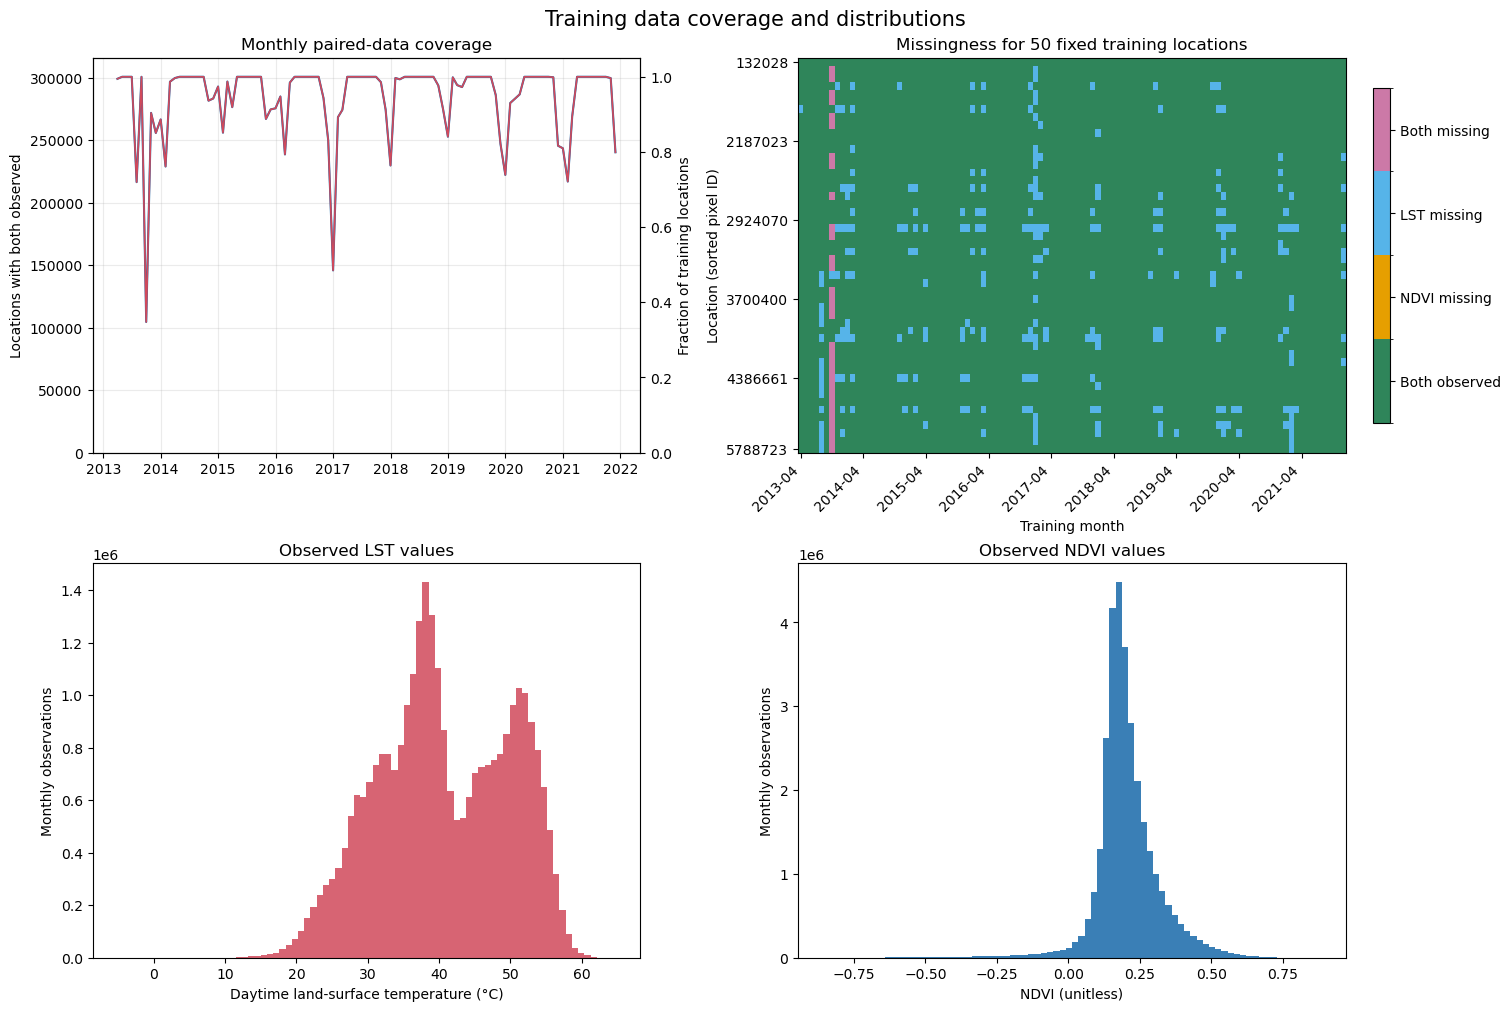

In [12]:
NDVI_OBSERVED = NDVI[np.isfinite(NDVI)]
LST_OBSERVED = LST[np.isfinite(LST)]
PAIRED = np.isfinite(NDVI) & np.isfinite(LST)
paired_count_by_month = PAIRED.sum(axis=0)
paired_fraction_by_month = paired_count_by_month / len(TRAINING_IDS)

summary_rows = []
for name, values, matrix in (
    ("NDVI", NDVI_OBSERVED, NDVI),
    ("LST (°C)", LST_OBSERVED, LST),
):
    summary_rows.append(
        {
            "Variable": name,
            "Missing training rows": int(np.isnan(matrix).sum()),
            "Observed minimum": float(values.min()),
            "Observed median": float(np.median(values)),
            "Observed maximum": float(values.max()),
        }
    )
distribution_summary = pd.DataFrame(summary_rows)
display(distribution_summary)
NDVI_LIMITS = (float(np.nanmin(NDVI)), float(np.nanmax(NDVI)))
LST_LIMITS = (float(np.nanmin(LST)), float(np.nanmax(LST)))

subset_rows = np.linspace(0, len(TRAINING_IDS) - 1, 50, dtype=int)
missing_codes = np.zeros((len(subset_rows), TRAINING_MONTHS), dtype=np.uint8)
ndvi_missing = ~np.isfinite(NDVI[subset_rows])
lst_missing = ~np.isfinite(LST[subset_rows])
missing_codes[ndvi_missing & ~lst_missing] = 1
missing_codes[~ndvi_missing & lst_missing] = 2
missing_codes[ndvi_missing & lst_missing] = 3

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
coverage_ax = axes[0, 0]
coverage_ax.plot(DATES, paired_count_by_month, color="#1769aa", linewidth=1.5)
coverage_ax.set_ylabel("Locations with both observed")
coverage_ax.set_title("Monthly paired-data coverage")
coverage_ax.set_ylim(0, len(TRAINING_IDS) * 1.05)
fraction_ax = coverage_ax.twinx()
fraction_ax.plot(DATES, paired_fraction_by_month, color="#d1495b", linewidth=1.2)
fraction_ax.set_ylabel("Fraction of training locations")
fraction_ax.set_ylim(0, 1.05)
coverage_ax.grid(alpha=0.25)

colors = ["#2f855a", "#e69f00", "#56b4e9", "#cc79a7"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)
heat_ax = axes[0, 1]
image = heat_ax.imshow(missing_codes, aspect="auto", interpolation="nearest", cmap=cmap, norm=norm)
heat_ax.set_title("Missingness for 50 fixed training locations")
heat_ax.set_ylabel("Location (sorted pixel ID)")
heat_ax.set_xlabel("Training month")
heat_ax.set_yticks(
    [0, 10, 20, 30, 40, 49],
    [str(TRAINING_IDS[subset_rows[i]]) for i in [0, 10, 20, 30, 40, 49]],
)
tick_positions = np.arange(0, TRAINING_MONTHS, 12)
heat_ax.set_xticks(tick_positions, [DATES[i].strftime("%Y-%m") for i in tick_positions], rotation=45, ha="right")
colorbar = fig.colorbar(image, ax=heat_ax, ticks=[0, 1, 2, 3], shrink=0.85)
colorbar.ax.set_yticklabels(["Both observed", "NDVI missing", "LST missing", "Both missing"])

axes[1, 0].hist(LST_OBSERVED, bins=80, color="#d1495b", alpha=0.85)
axes[1, 0].set(title="Observed LST values", xlabel="Daytime land-surface temperature (°C)", ylabel="Monthly observations")
axes[1, 1].hist(NDVI_OBSERVED, bins=80, color="#1769aa", alpha=0.85)
axes[1, 1].set(title="Observed NDVI values", xlabel="NDVI (unitless)", ylabel="Monthly observations")
fig.suptitle("Training data coverage and distributions", fontsize=15)
fig.savefig(FIGURE_DIR / "training_coverage_and_distributions.png", dpi=180)
plt.show()

del NDVI_OBSERVED, LST_OBSERVED

In [13]:
extreme_rows = []
for variable, matrix in (("ndvi", NDVI), ("lst", LST)):
    for label, flat_index in (
        ("minimum", int(np.nanargmin(matrix))),
        ("maximum", int(np.nanargmax(matrix))),
    ):
        location_index, date_index = np.unravel_index(flat_index, matrix.shape)
        date = DATES[date_index]
        value = float(matrix[location_index, date_index])
        source_path = SOURCE_DIR / f"evergreen_monthly_{date.year}.parquet"
        source_row = pq.read_table(
            source_path,
            columns=["pixel_id", "year", "month", variable],
            filters=[
                ("pixel_id", "=", int(TRAINING_IDS[location_index])),
                ("month", "=", int(date.month)),
            ],
        ).to_pandas()
        if len(source_row) != 1:
            raise ValueError(f"Expected one source row for pixel {TRAINING_IDS[location_index]} on {date:%Y-%m}.")
        source_value = float(source_row.iloc[0][variable])
        matches = source_value == value
        if not matches:
            raise ValueError(f"{variable} {label} does not match the annual source file.")
        extreme_rows.append(
            {
                "Variable": variable.upper(),
                "Extreme": label,
                "Value": value,
                "Pixel ID": int(TRAINING_IDS[location_index]),
                "Month": date.strftime("%Y-%m"),
                "Matches annual input": matches,
            }
        )

print("The observed minimum and maximum of each variable match their source records:")
display(pd.DataFrame(extreme_rows))

The observed minimum and maximum of each variable match their source records:


,Variable,Extreme,Value,Pixel ID,Month,Matches annual input
0,NDVI,minimum,-0.858487,4668732,2019-12,True
1,NDVI,maximum,0.884359,2199884,2018-01,True
2,LST,minimum,-5.110618,3983347,2021-03,True
3,LST,maximum,64.736618,2671655,2021-05,True


**How to read Figure 1.** Coverage changes show when fewer or more training locations have both measurements, so a change in observed temperatures should be considered alongside coverage. Histograms help check units and unusual values. The 50-location heatmap is a fixed diagnostic subset, not a reduction of the analysis data. Values are never discarded just for being extreme.

## 3. Locations and individual histories

Map color is each training location's median observed NDVI over April 2013–December 2021. The six histories are selected by a recorded rule: divide the coordinate extent into three longitude bands and two latitude bands; in each of the six cells, choose the location whose median NDVI is closest to a target quantile of the full training-location distribution. The target quantiles, in cell order, are 10%, 90%, 25%, 75%, 40%, and 60%. This gives a repeatable set spanning areas and lower-to-higher greenness.

Lines retain missing values as gaps. These examples show individual histories; they are not a representative sample for estimating a citywide trend.

,Geographic cell,Target greenness quantile,Pixel ID,Longitude,Latitude,Training median NDVI
0,1,0.10,1102772,54.405702,24.272704,0.133078
1,2,0.90,2592299,54.595695,24.467009,0.313662
2,3,0.25,1332506,54.704841,24.252761,0.158660
3,4,0.75,2820810,54.381717,24.499079,0.239074
4,5,0.40,2953688,54.570902,24.485335,0.174763
5,6,0.60,5529709,54.871388,24.828940,0.203465


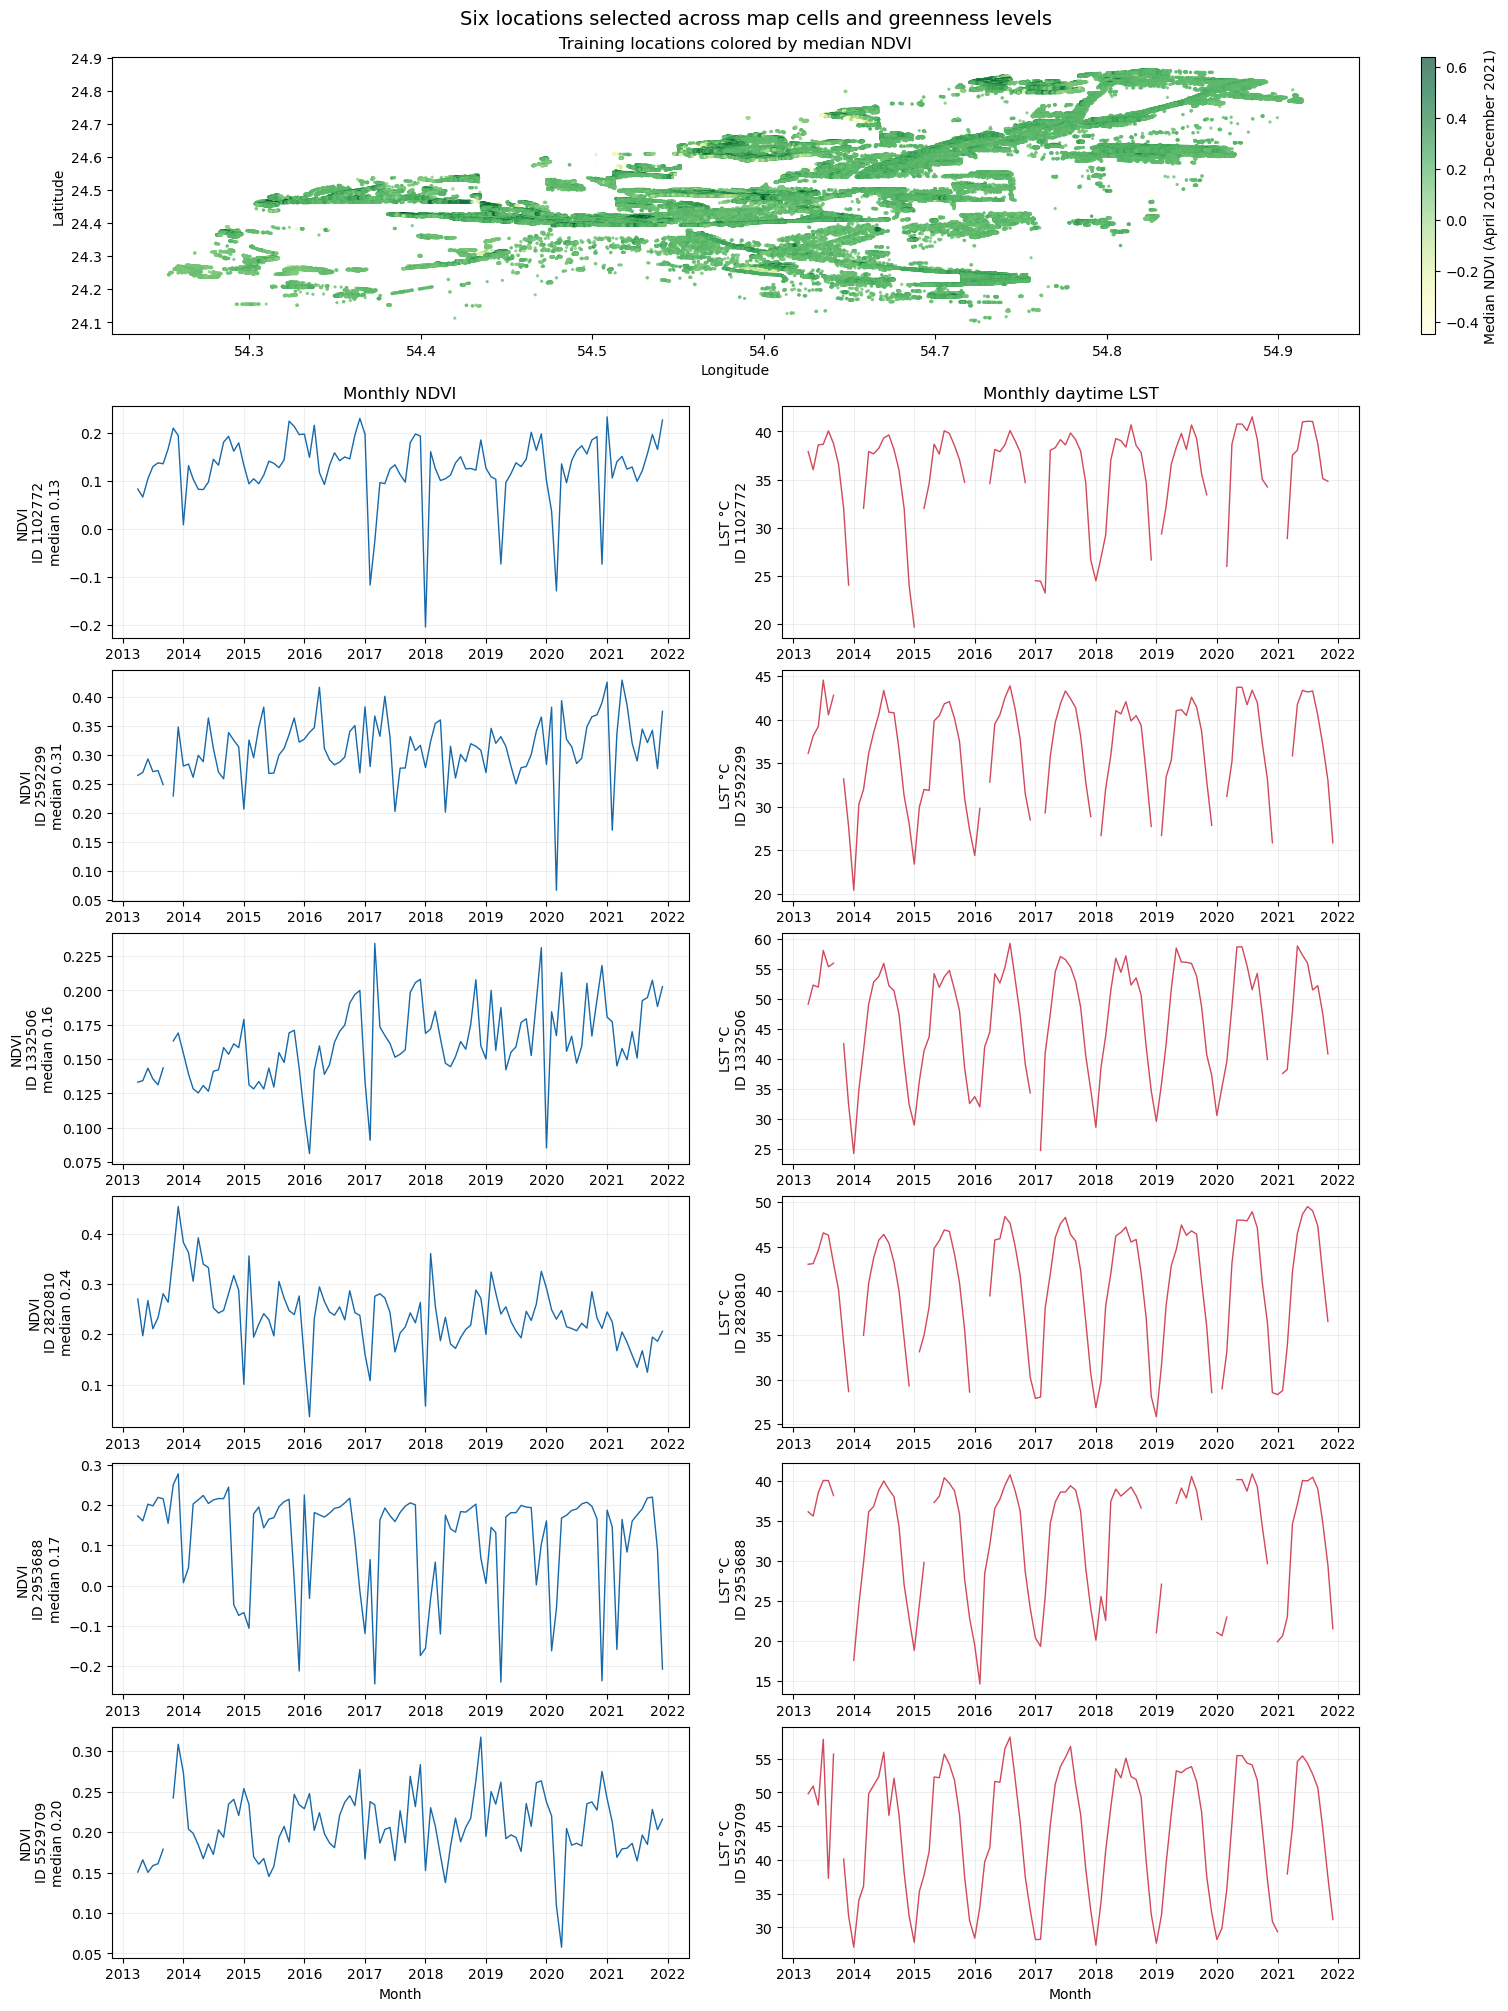

In [14]:
LOCATION_MEDIAN_NDVI = np.nanmedian(NDVI, axis=1)
if not np.isfinite(LOCATION_MEDIAN_NDVI).all():
    raise ValueError("Could not calculate a training-period median NDVI for every location.")

longitude_edges = np.linspace(LOCATION_LON.min(), LOCATION_LON.max(), 4)
latitude_edges = np.linspace(LOCATION_LAT.min(), LOCATION_LAT.max(), 3)
longitude_band = np.clip(np.digitize(LOCATION_LON, longitude_edges[1:-1]), 0, 2)
latitude_band = np.clip(np.digitize(LOCATION_LAT, latitude_edges[1:-1]), 0, 1)
target_quantiles = [0.10, 0.90, 0.25, 0.75, 0.40, 0.60]
target_values = np.quantile(LOCATION_MEDIAN_NDVI, target_quantiles)

history_indices = []
history_rows = []
cell_number = 0
for lat_band in range(2):
    for lon_band in range(3):
        candidates = np.flatnonzero((latitude_band == lat_band) & (longitude_band == lon_band))
        if len(candidates) == 0:
            raise ValueError(f"Geographic cell {cell_number + 1} has no training locations.")
        distance = np.abs(LOCATION_MEDIAN_NDVI[candidates] - target_values[cell_number])
        best_order = np.lexsort((TRAINING_IDS[candidates], distance))
        selected = int(candidates[best_order[0]])
        history_indices.append(selected)
        history_rows.append(
            {
                "Geographic cell": cell_number + 1,
                "Target greenness quantile": target_quantiles[cell_number],
                "Pixel ID": int(TRAINING_IDS[selected]),
                "Longitude": LOCATION_LON[selected],
                "Latitude": LOCATION_LAT[selected],
                "Training median NDVI": LOCATION_MEDIAN_NDVI[selected],
            }
        )
        cell_number += 1
history_selection = pd.DataFrame(history_rows)
display(history_selection)

fig = plt.figure(figsize=(15, 20), constrained_layout=True)
grid = fig.add_gridspec(7, 2, height_ratios=[1.2, 1, 1, 1, 1, 1, 1])
map_ax = fig.add_subplot(grid[0, :])
points = map_ax.scatter(
    LOCATION_LON,
    LOCATION_LAT,
    c=LOCATION_MEDIAN_NDVI,
    s=2,
    alpha=0.65,
    cmap="YlGn",
)
map_ax.set(title="Training locations colored by median NDVI", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(points, ax=map_ax, label="Median NDVI (April 2013–December 2021)")
history_axes = []
for row, location_index in enumerate(history_indices):
    if row == 0:
        left_ax = fig.add_subplot(grid[row + 1, 0])
        right_ax = fig.add_subplot(grid[row + 1, 1], sharex=left_ax)
    else:
        left_ax = fig.add_subplot(grid[row + 1, 0], sharex=history_axes[0][0])
        right_ax = fig.add_subplot(grid[row + 1, 1], sharex=history_axes[0][1])
    pixel_id = int(TRAINING_IDS[location_index])
    median_value = LOCATION_MEDIAN_NDVI[location_index]
    left_ax.plot(DATES, NDVI[location_index], color="#1769aa", linewidth=1)
    right_ax.plot(DATES, LST[location_index], color="#d1495b", linewidth=1)
    left_ax.set_ylabel(f"NDVI\nID {pixel_id}\nmedian {median_value:.2f}")
    right_ax.set_ylabel(f"LST °C\nID {pixel_id}")
    left_ax.grid(alpha=0.2)
    right_ax.grid(alpha=0.2)
    history_axes.append((left_ax, right_ax))
history_axes[0][0].set_title("Monthly NDVI")
history_axes[0][1].set_title("Monthly daytime LST")
for ax in history_axes[-1]:
    ax.set_xlabel("Month")
fig.suptitle("Six locations selected across map cells and greenness levels", fontsize=14)
fig.savefig(FIGURE_DIR / "training_locations_and_histories.png", dpi=180)
plt.show()

**How to read Figure 2.** The map can reveal geographic clustering in the observed training locations and in their median greenness. The histories show how NDVI and LST change over time at a few locations; gaps mean the measurement was missing. These plots describe patterns and do not establish that NDVI caused a temperature change.

## 4. Calendar months, seasons, and paired observations

The boxplots compare the distribution of observed values for each calendar month across training years. The relationship panels include only rows where both NDVI and LST are observed. Summer is derived as months 6–8 and winter as months 12, 1, and 2, directly from the `month` values; the stored season label is not used. All three hexbin panels use the same axes and color scale.

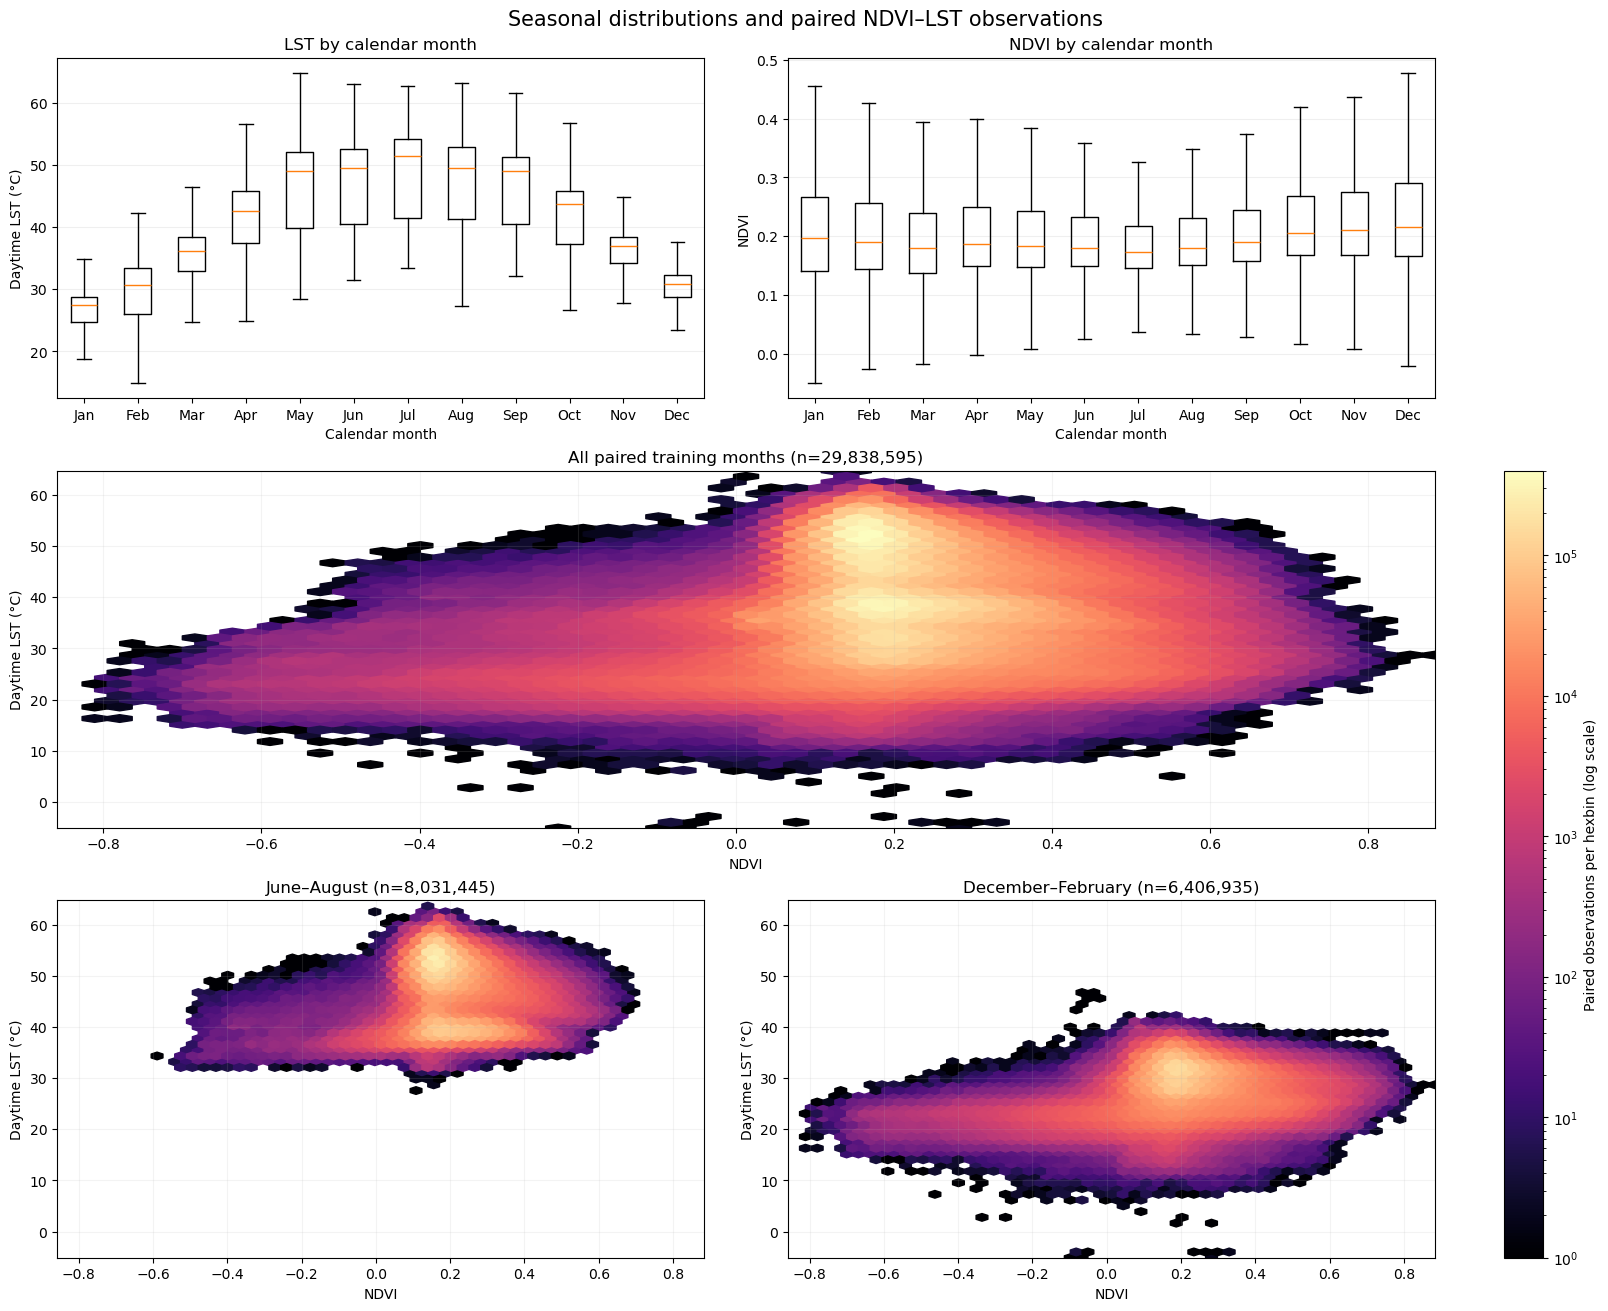

In [15]:
def monthly_box_stats(matrix, month_numbers):
    stats = []
    for month in range(1, 13):
        values = matrix[:, month_numbers == month].reshape(-1)
        values = values[np.isfinite(values)]
        q1, median, q3 = np.percentile(values, [25, 50, 75], overwrite_input=True)
        iqr = q3 - q1
        inside_whiskers = values[(values >= q1 - 1.5 * iqr) & (values <= q3 + 1.5 * iqr)]
        stats.append(
            {
                "label": calendar.month_abbr[month],
                "q1": float(q1),
                "med": float(median),
                "q3": float(q3),
                "whislo": float(inside_whiskers.min()),
                "whishi": float(inside_whiskers.max()),
                "fliers": [],
            }
        )
    return stats


def add_paired_hexbin(ax, month_set=None, gridsize=55):
    collection = None
    counts = None
    offsets = None
    paired_rows = 0
    extent = (NDVI_LIMITS[0], NDVI_LIMITS[1], LST_LIMITS[0], LST_LIMITS[1])
    for date_index, month in enumerate(MONTH_NUMBERS):
        if month_set is not None and month not in month_set:
            continue
        valid = PAIRED[:, date_index]
        if not valid.any():
            continue
        x = NDVI[valid, date_index]
        y = LST[valid, date_index]
        month_collection = ax.hexbin(
            x,
            y,
            gridsize=gridsize,
            extent=extent,
            mincnt=0,
            cmap="magma",
        )
        if collection is None:
            collection = month_collection
            offsets = collection.get_offsets().copy()
            counts = np.zeros_like(collection.get_array())
        else:
            if not np.array_equal(offsets, month_collection.get_offsets()):
                raise ValueError("Hexbin grids differ between training months.")
            month_collection.remove()
        counts += month_collection.get_array()
        paired_rows += len(x)
    if collection is None or counts is None:
        raise ValueError("No paired observations are available for this hexbin.")
    collection.set_array(counts)
    return collection, paired_rows


summer_months = {6, 7, 8}
winter_months = {12, 1, 2}
fig = plt.figure(figsize=(16, 13), constrained_layout=True)
grid = fig.add_gridspec(3, 2, height_ratios=[1, 1.05, 1.05])
lst_ax = fig.add_subplot(grid[0, 0])
ndvi_ax = fig.add_subplot(grid[0, 1])
lst_ax.bxp(monthly_box_stats(LST, MONTH_NUMBERS), showfliers=False)
ndvi_ax.bxp(monthly_box_stats(NDVI, MONTH_NUMBERS), showfliers=False)
lst_ax.set(title="LST by calendar month", ylabel="Daytime LST (°C)", xlabel="Calendar month")
ndvi_ax.set(title="NDVI by calendar month", ylabel="NDVI", xlabel="Calendar month")
for ax in (lst_ax, ndvi_ax):
    ax.grid(axis="y", alpha=0.2)

all_ax = fig.add_subplot(grid[1, :])
summer_ax = fig.add_subplot(grid[2, 0])
winter_ax = fig.add_subplot(grid[2, 1], sharex=summer_ax, sharey=summer_ax)
hexbin_panels = (
    (all_ax, None, "All paired training months"),
    (summer_ax, summer_months, "June–August"),
    (winter_ax, winter_months, "December–February"),
)
collections = []
for ax, season, title in hexbin_panels:
    collection, number_of_pairs = add_paired_hexbin(ax, season)
    collections.append(collection)
    ax.set(title=f"{title} (n={number_of_pairs:,})", xlabel="NDVI", ylabel="Daytime LST (°C)")
    ax.set_xlim(NDVI_LIMITS)
    ax.set_ylim(LST_LIMITS)
    ax.grid(alpha=0.15)
shared_norm = LogNorm(vmin=1, vmax=max(float(item.get_array().max()) for item in collections))
for item in collections:
    item.set_norm(shared_norm)
fig.colorbar(collections[0], ax=[all_ax, summer_ax, winter_ax], label="Paired observations per hexbin (log scale)")
fig.suptitle("Seasonal distributions and paired NDVI–LST observations", fontsize=15)
fig.savefig(FIGURE_DIR / "seasonal_relationships.png", dpi=180)
plt.show()

 **How to read Figure 3.** Monthly boxplots show seasonal variation in each variable. The paired hexbins show where the observed NDVI/LST combinations are concentrated; a hexagon’s color represents its number of paired monthly observations. Matching axes make the summer and winter panels comparable. Seasonal patterns can create an overall association even if there is no direct vegetation effect.

## 5. Two Pearson correlations

The first correlation uses every paired training pixel-month. The second first averages LST and NDVI within each pixel over exactly those paired training months, then correlates the pixel means. The table reports both the number of paired rows and the number of pixels represented. No p-values are used.

In [16]:
paired_rows = 0
sum_ndvi = sum_lst = sum_ndvi_sq = sum_lst_sq = sum_cross = 0.0
paired_months_per_pixel = np.zeros(len(TRAINING_IDS), dtype=np.int32)
ndvi_sum_per_pixel = np.zeros(len(TRAINING_IDS), dtype=np.float64)
lst_sum_per_pixel = np.zeros(len(TRAINING_IDS), dtype=np.float64)

for date_index in range(TRAINING_MONTHS):
    valid = PAIRED[:, date_index]
    x = NDVI[valid, date_index].astype(np.float64)
    y = LST[valid, date_index].astype(np.float64)
    paired_rows += len(x)
    sum_ndvi += x.sum()
    sum_lst += y.sum()
    sum_ndvi_sq += np.dot(x, x)
    sum_lst_sq += np.dot(y, y)
    sum_cross += np.dot(x, y)
    paired_months_per_pixel[valid] += 1
    ndvi_sum_per_pixel[valid] += x
    lst_sum_per_pixel[valid] += y

covariance_numerator = sum_cross - sum_ndvi * sum_lst / paired_rows
ndvi_variance_numerator = sum_ndvi_sq - sum_ndvi**2 / paired_rows
lst_variance_numerator = sum_lst_sq - sum_lst**2 / paired_rows
monthly_row_pearson = covariance_numerator / np.sqrt(
    ndvi_variance_numerator * lst_variance_numerator
)

pixels_with_pairs = paired_months_per_pixel > 0
mean_ndvi_by_pixel = ndvi_sum_per_pixel[pixels_with_pairs] / paired_months_per_pixel[pixels_with_pairs]
mean_lst_by_pixel = lst_sum_per_pixel[pixels_with_pairs] / paired_months_per_pixel[pixels_with_pairs]
pixel_mean_pearson = float(np.corrcoef(mean_ndvi_by_pixel, mean_lst_by_pixel)[0, 1])

correlation_table = pd.DataFrame(
    [
        {
            "Comparison": "All paired pixel-months",
            "Paired monthly rows used": paired_rows,
            "Pixels represented": int(pixels_with_pairs.sum()),
            "Pearson r": monthly_row_pearson,
        },
        {
            "Comparison": "Per-pixel means of paired months",
            "Paired monthly rows used": paired_rows,
            "Pixels represented": int(pixels_with_pairs.sum()),
            "Pearson r": pixel_mean_pearson,
        },
    ]
)
display(correlation_table)

sign_text = "the correlations have different signs" if np.sign(monthly_row_pearson) != np.sign(pixel_mean_pearson) else "the correlations have the same sign"
print(
    f"Description: row-level r = {monthly_row_pearson:.3f}; "
    f"pixel-mean r = {pixel_mean_pearson:.3f}; {sign_text}. "
    f"The absolute difference is {abs(monthly_row_pearson - pixel_mean_pearson):.3f}."
)
print(
    "The row-level value mixes differences across locations with changes over time. "
    "The pixel-mean value describes how average conditions differ across locations. "
    "Neither is evidence of cooling caused by vegetation or proof of predictive performance. "
    "Repeated observations are spatially and temporally related, not independent replications."
)

,Comparison,Paired monthly rows used,Pixels represented,Pearson r
0,All paired pixel-months,29838595,300582,-0.072168
1,Per-pixel means of paired months,29838595,300582,-0.091667


Description: row-level r = -0.072; pixel-mean r = -0.092; the correlations have the same sign. The absolute difference is 0.019.
The row-level value mixes differences across locations with changes over time. The pixel-mean value describes how average conditions differ across locations. Neither is evidence of cooling caused by vegetation or proof of predictive performance. Repeated observations are spatially and temporally related, not independent replications.


## 6. Monthly paired-support means and coverage

For each of the 105 calendar months, this calculates mean LST and mean NDVI across training locations where both measurements are observed. Both monthly means use the same paired locations. The paired-location count is retained for every month, so changing coverage is visible.


In [17]:
paired_count_by_month = PAIRED.sum(axis=0)
ndvi_sum_by_month = np.where(PAIRED, NDVI, 0.0).sum(axis=0, dtype=np.float64)
lst_sum_by_month = np.where(PAIRED, LST, 0.0).sum(axis=0, dtype=np.float64)
monthly_mean_ndvi = np.divide(
    ndvi_sum_by_month,
    paired_count_by_month,
    out=np.full(TRAINING_MONTHS, np.nan, dtype=np.float64),
    where=paired_count_by_month > 0,
)
monthly_mean_lst = np.divide(
    lst_sum_by_month,
    paired_count_by_month,
    out=np.full(TRAINING_MONTHS, np.nan, dtype=np.float64),
    where=paired_count_by_month > 0,
)
monthly = pd.DataFrame(
    {
        "date": DATES,
        "paired_location_count": paired_count_by_month,
        "mean_ndvi": monthly_mean_ndvi,
        "mean_lst_c": monthly_mean_lst,
        "months_since_apr_2013": np.arange(TRAINING_MONTHS),
    }
)
monthly["tau_decades"] = monthly["months_since_apr_2013"] / 120.0
monthly["calendar_month"] = monthly["date"].dt.month

tau = monthly["tau_decades"].to_numpy(dtype=np.float64)
calendar_month = monthly["calendar_month"].to_numpy(dtype=np.int64)
design = np.column_stack(
    [
        np.ones(TRAINING_MONTHS),
        tau,
        *[(calendar_month == month).astype(np.float64) for month in range(2, 13)],
    ]
)
observed_months = monthly["mean_lst_c"].notna().to_numpy()
if not np.array_equal(observed_months, monthly["mean_ndvi"].notna().to_numpy()):
    raise ValueError("NDVI and LST monthly means must use the same paired observations.")
if observed_months.sum() <= design.shape[1]:
    raise ValueError("Not enough observed monthly means to fit the trend model.")

ndvi_fit = sm.OLS(
    monthly.loc[observed_months, "mean_ndvi"].to_numpy(dtype=np.float64),
    design[observed_months],
).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
lst_fit = sm.OLS(
    monthly.loc[observed_months, "mean_lst_c"].to_numpy(dtype=np.float64),
    design[observed_months],
).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
if ndvi_fit.model.rank < design.shape[1] or lst_fit.model.rank < design.shape[1]:
    raise ValueError("The monthly trend design matrix is not full rank.")

for variable, fit in (("ndvi", ndvi_fit), ("lst_c", lst_fit)):
    seasonal_component = design[:, 2:] @ fit.params[2:]
    mean_seasonal_component = float(seasonal_component[observed_months].mean())
    monthly[f"fitted_seasonal_component_{variable}"] = seasonal_component
    monthly[f"season_adjusted_mean_{variable}"] = (
        monthly[f"mean_{variable}"] - seasonal_component + mean_seasonal_component
    )
    monthly[f"fitted_trend_{variable}"] = (
        fit.params[0] + fit.params[1] * tau + mean_seasonal_component
    )
    confidence_interval = fit.conf_int(alpha=0.05)[1]
    monthly[f"slope_{variable}_per_decade"] = fit.params[1]
    monthly[f"slope_{variable}_ci95_lower"] = confidence_interval[0]
    monthly[f"slope_{variable}_ci95_upper"] = confidence_interval[1]

monthly.to_csv(MONTHLY_TABLE_PATH, index=False, date_format="%Y-%m-%d")
print(f"Training period: {DATES[0]:%Y-%m} through {DATES[-1]:%Y-%m}")
print(f"Training locations: {len(TRAINING_IDS):,}; spatial-test locations excluded")
print(f"Calendar months: {len(monthly)}; fitted monthly means: {int(observed_months.sum())}")
print(f"Total paired location-month observations: {int(paired_count_by_month.sum()):,}")
for label, fit in (("NDVI", ndvi_fit), ("LST", lst_fit)):
    low, high = fit.conf_int(alpha=0.05)[1]
    print(f"Season-adjusted {label} slope: {fit.params[1]:+.3f} (95% HAC CI {low:+.3f}, {high:+.3f}) per decade")
print("HAC covariance uses 12 monthly lags; it does not include all satellite or sample uncertainty.")
print(f"Saved monthly table: {MONTHLY_TABLE_PATH}")
display(monthly.head(3))
display(monthly.tail(3))

Training period: 2013-04 through 2021-12
Training locations: 300,582; spatial-test locations excluded
Calendar months: 105; fitted monthly means: 105
Total paired location-month observations: 29,838,595
Season-adjusted NDVI slope: +0.023 (95% HAC CI +0.009, +0.037) per decade
Season-adjusted LST slope: +1.273 (95% HAC CI +0.664, +1.881) per decade
HAC covariance uses 12 monthly lags; it does not include all satellite or sample uncertainty.
Saved monthly table: /Users/meera/greening_predictive/reports/training_monthly_lst_means.csv


,date,paired_location_count,mean_ndvi,mean_lst_c,months_since_apr_2013,tau_decades,calendar_month,fitted_seasonal_component_ndvi,season_adjusted_mean_ndvi,fitted_trend_ndvi,slope_ndvi_per_decade,slope_ndvi_ci95_lower,slope_ndvi_ci95_upper,fitted_seasonal_component_lst_c,season_adjusted_mean_lst_c,fitted_trend_lst_c,slope_lst_c_per_decade,slope_lst_c_ci95_lower,slope_lst_c_ci95_upper
0,2013-04-01,298970,0.184312,43.624065,0,0.000000,4,0.004352,0.183504,0.195206,0.02294,0.008554,0.037327,15.162839,42.091294,39.630575,1.272654,0.664218,1.881091
1,2013-05-01,300582,0.169753,44.406489,1,0.008333,5,0.002299,0.170998,0.195398,0.02294,0.008554,0.037327,20.349431,37.687127,39.641181,1.272654,0.664218,1.881091
2,2013-06-01,300582,0.188777,45.189777,2,0.016667,6,-0.003545,0.195866,0.195589,0.02294,0.008554,0.037327,20.968661,37.851184,39.651786,1.272654,0.664218,1.881091


,date,paired_location_count,mean_ndvi,mean_lst_c,months_since_apr_2013,tau_decades,calendar_month,fitted_seasonal_component_ndvi,season_adjusted_mean_ndvi,fitted_trend_ndvi,slope_ndvi_per_decade,slope_ndvi_ci95_lower,slope_ndvi_ci95_upper,fitted_seasonal_component_lst_c,season_adjusted_mean_lst_c,fitted_trend_lst_c,slope_lst_c_per_decade,slope_lst_c_ci95_lower,slope_lst_c_ci95_upper
102,2021-10-01,300581,0.238057,41.649209,102,0.850000,10,0.019346,0.222255,0.214706,0.02294,0.008554,0.037327,15.307450,39.971827,40.712332,1.272654,0.664218,1.881091
103,2021-11-01,299511,0.212547,36.247577,103,0.858333,11,0.019841,0.196250,0.214897,0.02294,0.008554,0.037327,9.457415,40.420231,40.722937,1.272654,0.664218,1.881091
104,2021-12-01,240215,0.218700,29.643377,104,0.866667,12,0.025215,0.197029,0.215088,0.02294,0.008554,0.037327,3.468157,39.805289,40.733542,1.272654,0.664218,1.881091


## 7. Season-adjusted aggregate trend figure

This reproduces the supplied reference layout with two panels: monthly mean NDVI and LST on the same paired-location support. Each series has its usual calendar-month pattern removed using the regression with elapsed months divided by 120 and February–December indicators (January reference). The dashed line shows the estimated long-term trend. Annotations report the trend and 95% HAC confidence interval using 12 monthly lags. The NDVI panel marks its observed minimum in this training period; the cause is not identified. HAC accounts for serial dependence between nearby months but not all satellite or sample uncertainty. Season adjustment is only for this trend exercise; raw LST remains the later prediction target.


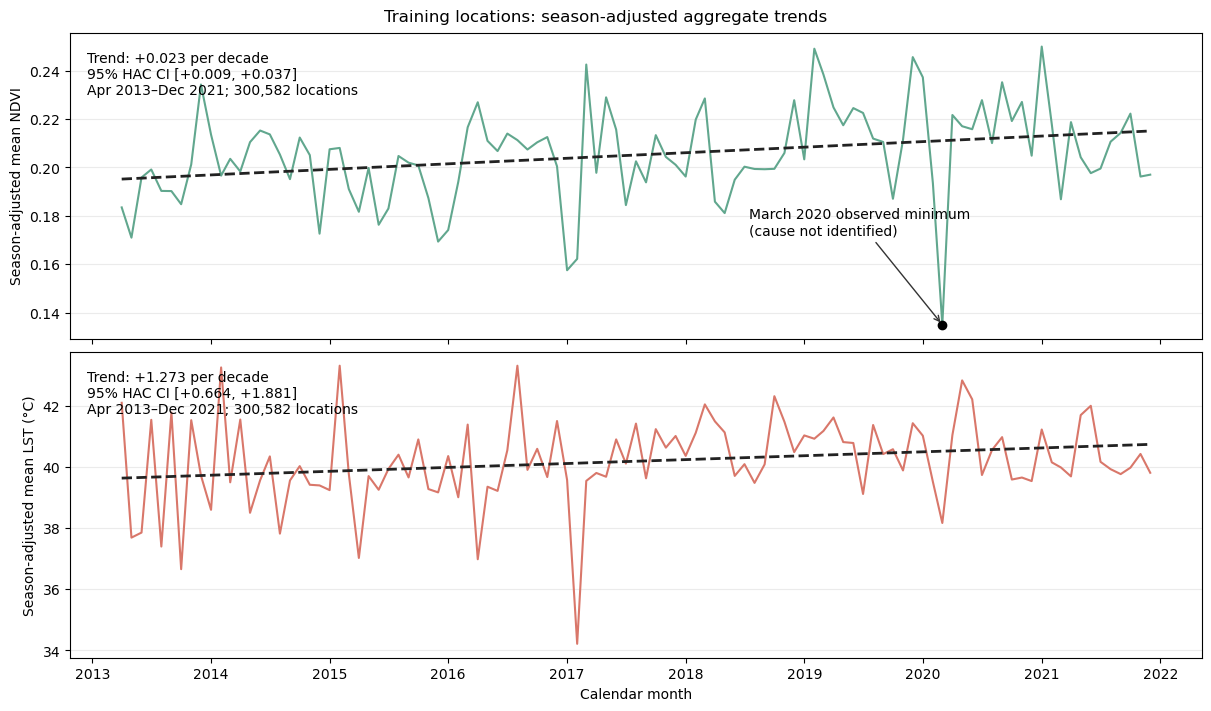

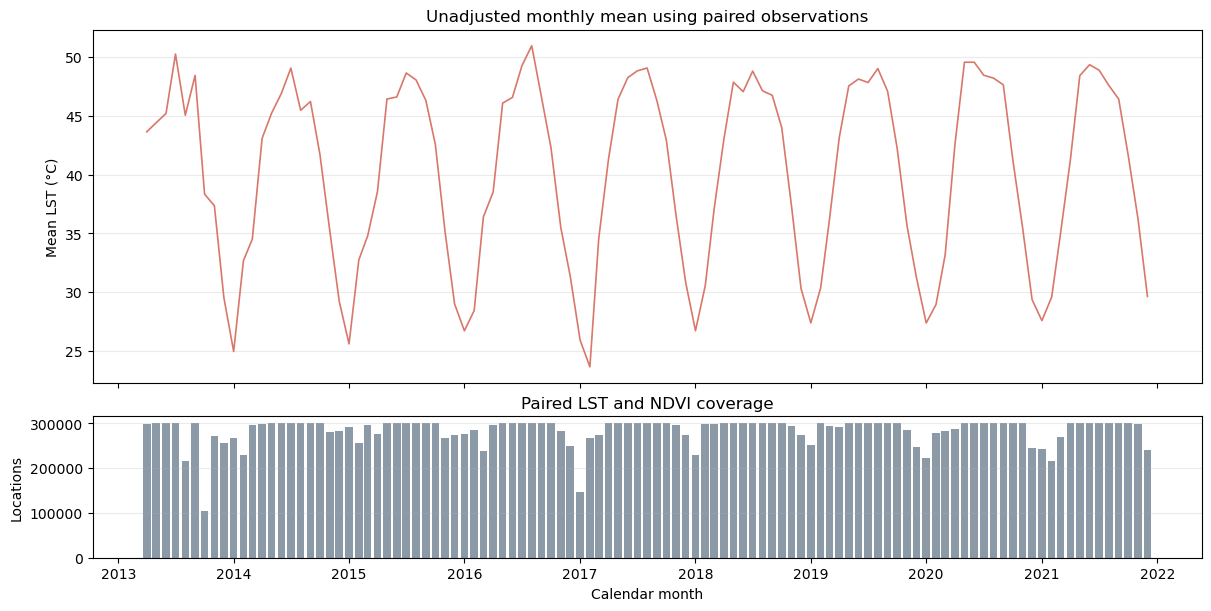

In [18]:
trend_figure, trend_axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)

for ax, variable, fit, color, ylabel in (
    (trend_axes[0], "ndvi", ndvi_fit, "#61a78e", "Season-adjusted mean NDVI"),
    (trend_axes[1], "lst_c", lst_fit, "#d9776a", "Season-adjusted mean LST (°C)"),
):
    ax.plot(monthly["date"], monthly[f"season_adjusted_mean_{variable}"], color=color, linewidth=1.5)
    ax.plot(monthly["date"], monthly[f"fitted_trend_{variable}"], color="#222222", linestyle="--", linewidth=2)
    slope = fit.params[1]
    ci_lower, ci_upper = fit.conf_int(alpha=0.05)[1]
    annotation = (
        f"Trend: {slope:+.3f} per decade\n"
        f"95% HAC CI [{ci_lower:+.3f}, {ci_upper:+.3f}]\n"
        f"{DATES[0]:%b %Y}–{DATES[-1]:%b %Y}; {len(TRAINING_IDS):,} locations"
    )
    ax.text(0.015, 0.94, annotation, transform=ax.transAxes, ha="left", va="top")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)

minimum_index = monthly["season_adjusted_mean_ndvi"].idxmin()
minimum_date = monthly.loc[minimum_index, "date"]
minimum_value = monthly.loc[minimum_index, "season_adjusted_mean_ndvi"]
trend_axes[0].scatter([minimum_date], [minimum_value], color="black", zorder=3)
trend_axes[0].annotate(
    f"{minimum_date:%B %Y} observed minimum\n(cause not identified)",
    xy=(minimum_date, minimum_value),
    xytext=(0.60, 0.34),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "#333333"},
)
trend_axes[-1].set_xlabel("Calendar month")
trend_axes[-1].xaxis.set_major_locator(mdates.YearLocator())
trend_axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
trend_figure.suptitle("Training locations: season-adjusted aggregate trends")
trend_figure.savefig(FIGURE_DIR / "season_adjusted_aggregate_trends.png", dpi=180)
plt.show()

coverage_figure, coverage_axes = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True,
    gridspec_kw={"height_ratios": [2, 0.8]}, constrained_layout=True,
)
coverage_axes[0].plot(monthly["date"], monthly["mean_lst_c"], color="#d9776a", linewidth=1.2)
coverage_axes[0].set_ylabel("Mean LST (°C)")
coverage_axes[0].set_title("Unadjusted monthly mean using paired observations")
coverage_axes[0].grid(axis="y", alpha=0.25)
coverage_axes[1].bar(monthly["date"], monthly["paired_location_count"], width=24, color="#8c9aa8")
coverage_axes[1].set_ylabel("Locations")
coverage_axes[1].set_title("Paired LST and NDVI coverage")
coverage_axes[1].grid(axis="y", alpha=0.25)
coverage_axes[-1].set_xlabel("Calendar month")
coverage_axes[-1].xaxis.set_major_locator(mdates.YearLocator())
coverage_axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
coverage_figure.savefig(FIGURE_DIR / "training_monthly_lst_coverage.png", dpi=180)
plt.show()

## 8. Proposed model-comparison plan

**Research question:** does NDVI improve prediction of raw daytime LST beyond season and location? This is a prediction comparison, not a causal analysis. The decisions below are proposals and remain pending supervisor approval.

- **Main sample:** eligible development locations with the existing fixed spatial assignment.
- **Models:** use the same model method, rows, evaluation metrics, and agreed calendar/location inputs; add NDVI as the only planned difference in the comparison model.
- **Time split:** fit on 2013–2021, use 2022 for model choices, and keep 2023–2024 outcomes closed until choices are frozen.
- **Spatial test:** keep spatial-test LST closed until choices are frozen; report unseen-area performance separately.
- **Weather:** omit it from both models unless suitable, checked weather data become available.
- **Robustness:** verify identical row support, report results by time period and geographic split, and consider a different block/buffer design only if approved.